# $L = 6$ scan

Disorder average on the periodic $6\times 6$ torus, $N = 108$. Four stored draws $z_b$, samples 0–3, are shared by every width: $J_b = \sigma z_b$ and $h = 0$. The widths are $\sigma = 0.05, 0.1, 0.2, 0.5, 1, 2$. $\Gamma/\sigma$ runs from 0.05 to 3.

Each drawn point is the jackknife mean over the four samples at that $(\sigma, \Gamma/\sigma)$. $[\langle q^2\rangle]$ is the disorder average of the forward-walked overlap. The Binder cumulant is formed on each sample,

$$B = \tfrac{1}{2}\left(3 - \frac{\langle q^4\rangle}{\langle q^2\rangle^2}\right),$$

and then averaged. The dashed line is $1/N$.

$H(\sigma, \Gamma) = \sigma\, H(1, \Gamma/\sigma)$, so these dimensionless quantities should fall on one curve against $\Gamma/\sigma$. Markers at the same $\Gamma/\sigma$ are shifted by a small offset so the six widths stay visible. A point is drawn only when all four samples are on disk.


In [1]:
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd()
if not (root / "data").exists():
    root = root.parent
sys.path.insert(0, str(root / "code"))

from kagome_qea.observables import jackknife_disorder_binder, jackknife_mean_error

base = root / "data" / "kagome" / "gaussian_nn" / "pbc" / "L6" / "pqmc" / "h0"
n_sites = 108
rows = []
for path in sorted(base.glob("sigma*/gamma*/sample*_seed0.npz")):
    with np.load(path) as data:
        sigma = float(data["sigma"])
        gamma = float(data["gamma"])
        rows.append({
            "sigma": sigma,
            "gamma": gamma,
            "ratio": gamma / sigma,
            "q2": float(data["q2"]),
            "q4": float(data["q4"]),
            "ancestors": int(data["min_unique_ancestors"]),
        })

groups = defaultdict(list)
for row in rows:
    groups[(row["sigma"], round(row["ratio"], 6))].append(row)

points = []
skipped = []
for (sigma, ratio), group in sorted(groups.items()):
    if len(group) < 4:
        skipped.append((sigma, ratio, len(group)))
        continue
    q2 = np.array([row["q2"] for row in group], dtype=np.float64)
    q4 = np.array([row["q4"] for row in group], dtype=np.float64)
    binder, binder_error = jackknife_disorder_binder(q2, q4)
    points.append({
        "sigma": sigma,
        "gamma": float(np.mean([row["gamma"] for row in group])),
        "ratio": float(ratio),
        "q2": float(q2.mean()),
        "q2_error": jackknife_mean_error(q2),
        "binder": binder,
        "binder_error": binder_error,
        "ancestors": int(min(row["ancestors"] for row in group)),
    })

print(f"files {len(rows)}  drawn points {len(points)}")
for sigma, ratio, count in skipped:
    print(f"skipped sigma {sigma:g}  ratio {ratio:g}  samples {count}")

spread = 0.0
by_ratio = defaultdict(list)
for row in points:
    by_ratio[row["ratio"]].append(row["q2"])
for values in by_ratio.values():
    spread = max(spread, max(values) - min(values))
print(f"max q2 spread across sigma at fixed Gamma/sigma: {spread:.3e}")
print(f"minimum ancestors on drawn points: {min(row['ancestors'] for row in points)}")
print("table is sigma = 1; the other widths match these q2 values")
print(f"{'sigma':>6} {'Gamma':>8} {'ratio':>7} {'q2':>8} {'err':>8} {'B':>8} {'Berr':>8} {'anc':>4}")
for row in points:
    if abs(row["sigma"] - 1.0) > 1e-8:
        continue
    print(
        f"{row['sigma']:6g} {row['gamma']:8.4f} {row['ratio']:7.2f} "
        f"{row['q2']:8.4f} {row['q2_error']:8.4f} "
        f"{row['binder']:8.3f} {row['binder_error']:8.3f} {row['ancestors']:4d}"
    )


files 350  drawn points 87
skipped sigma 2  ratio 2  samples 1
skipped sigma 2  ratio 3  samples 1
max q2 spread across sigma at fixed Gamma/sigma: 0.000e+00
minimum ancestors on drawn points: 1
table is sigma = 1; the other widths match these q2 values
 sigma    Gamma   ratio       q2      err        B     Berr  anc
     1   0.0500    0.05   0.0063   0.0018    0.401    0.161    1
     1   0.1000    0.10   0.0681   0.0238    0.740    0.102    1
     1   0.1500    0.15   0.0315   0.0086    0.463    0.100    1
     1   0.2000    0.20   0.0399   0.0102    0.260    0.225    1
     1   0.3000    0.30   0.0197   0.0039    0.488    0.040    1
     1   0.4000    0.40   0.0202   0.0015   -0.101    0.226    1
     1   0.5000    0.50   0.0173   0.0016    0.317    0.112    1
     1   0.6000    0.60   0.0131   0.0024    0.280    0.142    1
     1   0.8000    0.80   0.0128   0.0017    0.330    0.081    1
     1   1.0000    1.00   0.0110   0.0006    0.173    0.219    1
     1   1.2500    1.25   0.012

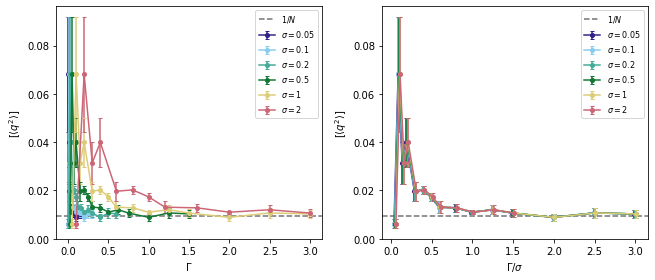

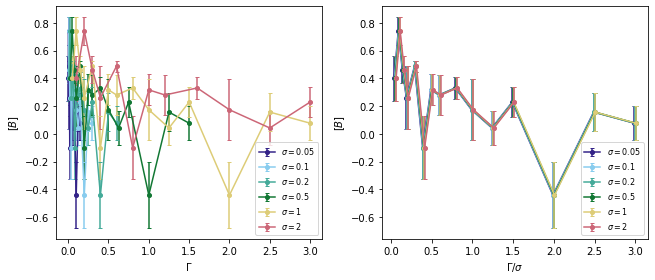

In [2]:
colors = {
    0.05: "#332288",
    0.1: "#88CCEE",
    0.2: "#44AA99",
    0.5: "#117733",
    1.0: "#DDCC77",
    2.0: "#CC6677",
}

def color_for(sigma):
    for key, color in colors.items():
        if abs(key - sigma) < 1e-8:
            return color
    raise KeyError(sigma)

sigmas = sorted({row["sigma"] for row in points})
offsets = {
    sigma: float(offset)
    for sigma, offset in zip(sigmas, np.linspace(-0.012, 0.012, len(sigmas)))
}

def draw(quantity, error_name, ylabel):
    figure, axes = plt.subplots(1, 2, figsize=(9.2, 4.0))
    for sigma in sigmas:
        group = sorted(
            (row for row in points if abs(row["sigma"] - sigma) < 1e-8),
            key=lambda row: row["ratio"],
        )
        label = rf"$\sigma = {sigma:g}$"
        axes[0].errorbar(
            [row["gamma"] for row in group],
            [row[quantity] for row in group],
            yerr=[row[error_name] for row in group],
            fmt="o-",
            ms=4,
            capsize=2,
            color=color_for(sigma),
            label=label,
        )
        axes[1].errorbar(
            [row["ratio"] + offsets[sigma] for row in group],
            [row[quantity] for row in group],
            yerr=[row[error_name] for row in group],
            fmt="o-",
            ms=4,
            capsize=2,
            color=color_for(sigma),
            label=label,
        )
    if quantity == "q2":
        for axis in axes:
            axis.axhline(1.0 / n_sites, color="0.45", linestyle="--", label="$1/N$")
            axis.set_ylim(bottom=0.0)
    for axis in axes:
        axis.set_ylabel(ylabel)
        axis.legend(fontsize=8)
    axes[0].set_xlabel(r"$\Gamma$")
    axes[1].set_xlabel(r"$\Gamma/\sigma$")
    figure.tight_layout()
    plt.show()

draw("q2", "q2_error", r"$[\langle q^{2}\rangle]$")
draw("binder", "binder_error", r"$[B]$")
